In [323]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [324]:
data=pd.read_csv('vgsales.csv')
df=data.copy()
df.head(10)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
5,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
6,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
7,8,Wii Play,Wii,2006.0,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009.0,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62
9,10,Duck Hunt,NES,1984.0,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31


In [325]:
df.shape

(16598, 11)

In [326]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [327]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [328]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [329]:
df[df['Year'].isnull()]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
179,180,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
377,378,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,0.59,2.36,0.04,0.51,3.49
431,432,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1.86,1.02,0.00,0.29,3.17
470,471,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00
607,608,Space Invaders,2600,NaN,Shooter,Atari,2.36,0.14,0.00,0.03,2.53
...,...,...,...,...,...,...,...,...,...,...,...
16307,16310,Freaky Flyers,GC,NaN,Racing,Unknown,0.01,0.00,0.00,0.00,0.01
16327,16330,Inversion,PC,NaN,Shooter,Namco Bandai Games,0.01,0.00,0.00,0.00,0.01
16366,16369,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,Unknown,0.01,0.00,0.00,0.00,0.01
16427,16430,Virtua Quest,GC,NaN,Role-Playing,Unknown,0.01,0.00,0.00,0.00,0.01


Here we see there are some missing values in Year and Publisher..let's handle them first.

In [330]:
# Investigate missing year records
missing_year = df[df['Year'].isnull()]

print("Missing year records:", len(missing_year))

# Check their sales contribution
print(
    missing_year['Global_Sales'].sum()
)

# Check their sales distribution
print(
    missing_year['Global_Sales'].describe()
)

Missing year records: 271
100.08000000000001
count    271.000000
mean       0.369299
std        0.615113
min        0.010000
25%        0.055000
50%        0.160000
75%        0.395000
max        5.230000
Name: Global_Sales, dtype: float64


In [331]:
print("Missing year sales:", missing_year['Global_Sales'].sum())

print(
    "Known year sales:",
    df[df['Year'].notnull()]['Global_Sales'].sum()
)

Missing year sales: 100.08000000000001
Known year sales: 8820.360000000002


In [332]:
missing_sales_percentage = (
    missing_year['Global_Sales'].sum()
    / df['Global_Sales'].sum()
) * 100

print(f"Missing-year sales contribution: {missing_sales_percentage:.2f}%")

Missing-year sales contribution: 1.12%


In [333]:
df.dropna(subset=['Year'],axis=0,inplace=True)

In [334]:
#dimension of the dataset after droping the null values. Previously it was 16598 x 11
df.shape

(16327, 11)

A total of 271 records (approximately 1.63% of the dataset) had missing release-year values. These records accounted for approximately 1.12% of total global sales. Since release year is essential for time-based analysis, these records were excluded from temporal analysis.

In [335]:
# changing the datatype of year from float to int
df['Year'] = df['Year'].astype('int')

In [336]:
df['Publisher'].fillna(value='Unknown',inplace=True)

C:\Users\priya\AppData\Local\Temp\ipykernel_16928\177374474.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Publisher'].fillna(value='Unknown',inplace=True)


In [337]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

Missing values in the Publisher column were replaced with "Unknown" to preserve the records and avoid unnecessary data loss.


### Knowing the unique items in different catergories

In [338]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

In [339]:
df['Name'].unique()

array(['Wii Sports', 'Super Mario Bros.', 'Mario Kart Wii', ...,
       'Plushees', 'Woody Woodpecker in Crazy Castle 5', 'Know How 2'],
      shape=(11360,), dtype=object)

In [340]:
df['Platform'].unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       '3DS', 'PS4', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne', 'GC',
       'WiiU', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

In [341]:
len(df['Publisher'].unique())

576

In [342]:
len(df['Rank'].unique())

16327

In [343]:
df['Genre'].unique()

array(['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', 'Misc',
       'Shooter', 'Simulation', 'Action', 'Fighting', 'Adventure',
       'Strategy'], dtype=object)

### Finding the top 5 of the catergorical datas


In [344]:
df['Publisher'].value_counts().head()

Publisher
Electronic Arts                 1339
Activision                       966
Namco Bandai Games               928
Ubisoft                          918
Konami Digital Entertainment     823
Name: count, dtype: int64

In [345]:
top_5_publi=df['Publisher'].value_counts().index[:5]
top_5_publi

Index(['Electronic Arts', 'Activision', 'Namco Bandai Games', 'Ubisoft',
       'Konami Digital Entertainment'],
      dtype='object', name='Publisher')

In [346]:
df['Platform'].value_counts().head(10)

Platform
DS      2133
PS2     2127
PS3     1304
Wii     1290
X360    1235
PSP     1197
PS      1189
PC       943
GBA      811
XB       803
Name: count, dtype: int64

In [347]:
top_5_plat=df['Platform'].value_counts().index[:5]
top_5_plat

Index(['DS', 'PS2', 'PS3', 'Wii', 'X360'], dtype='object', name='Platform')

In [348]:
df['Genre'].value_counts().head()

Genre
Action          3253
Sports          2304
Misc            1710
Role-Playing    1471
Shooter         1282
Name: count, dtype: int64

In [349]:
top_5_gen=df['Genre'].value_counts().index[:5]
top_5_gen

Index(['Action', 'Sports', 'Misc', 'Role-Playing', 'Shooter'], dtype='object', name='Genre')

### Variation of different sales over the years


In [350]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='object')

In [351]:
df['Year'].unique()

array([2006, 1985, 2008, 2009, 1996, 1989, 1984, 2005, 1999, 2007, 2010,
       2013, 2004, 1990, 1988, 2002, 2001, 2011, 1998, 2015, 2012, 2014,
       1992, 1997, 1993, 1994, 1982, 2003, 1986, 2000, 1995, 2016, 1991,
       1981, 1987, 1980, 1983, 2020, 2017])

In [352]:
yearly_na_sales=df.groupby('Year')['NA_Sales'].sum()
yearly_eu_sales=df.groupby('Year')['EU_Sales'].sum()
yearly_jp_sales=df.groupby('Year')['JP_Sales'].sum()
yearly_other_sales=df.groupby('Year')['Other_Sales'].sum()
yearly_global_sales=df.groupby('Year')['Global_Sales'].sum()


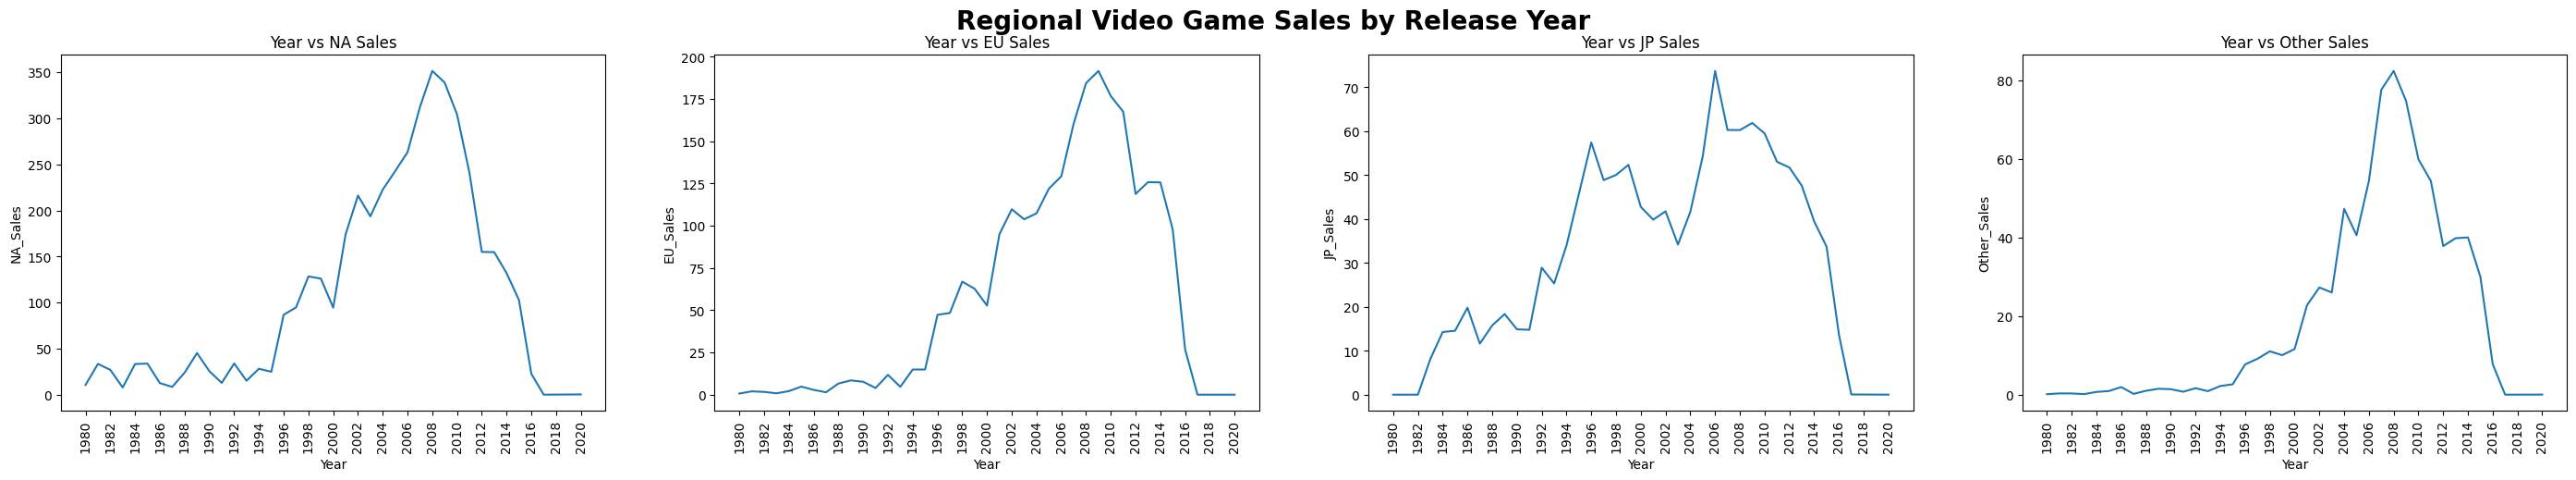

In [425]:
fig, ax=plt.subplots(1,4,figsize=(35,5))
fig.suptitle('Regional Video Game Sales by Release Year', fontsize=20, fontweight='bold')

ax[0].plot(yearly_na_sales.index,yearly_na_sales.values)
ax[0].set_title('Year vs NA Sales')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('NA_Sales')

ax[1].plot(yearly_eu_sales.index,yearly_eu_sales.values)
ax[1].set_title('Year vs EU Sales')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('EU_Sales')

ax[2].plot(yearly_jp_sales.index,yearly_jp_sales.values)
ax[2].set_title('Year vs JP Sales')
ax[2].set_xlabel('Year')
ax[2].set_ylabel('JP_Sales')

ax[3].plot(yearly_other_sales.index,yearly_other_sales.values)
ax[3].set_title('Year vs Other Sales')
ax[3].set_xlabel('Year')
ax[3].set_ylabel('Other_Sales')

years = np.arange(1980, 2021, 2)   

for a in ax:
    a.set_xticks(years)
    a.tick_params(axis='x', rotation=90)



Based on your charts:
- North American and European sales peak around 2008–2009.
- Japanese sales peak around 2006.
- Other-region sales also peak around 2008–2009.
- Sales decline considerably after these peak years.

### Handling Outliers

In [354]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16327.000000,16327.000000,16327.000000,16327.000000,16327.000000,16327.000000,16327.000000
mean,8292.868194,2006.406443,0.265415,0.147554,0.078661,0.048325,0.540232
std,4792.669778,5.828981,0.821591,0.508766,0.311557,0.189885,1.565732
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4136.500000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8295.000000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12441.500000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


<Axes: ylabel='Global_Sales'>

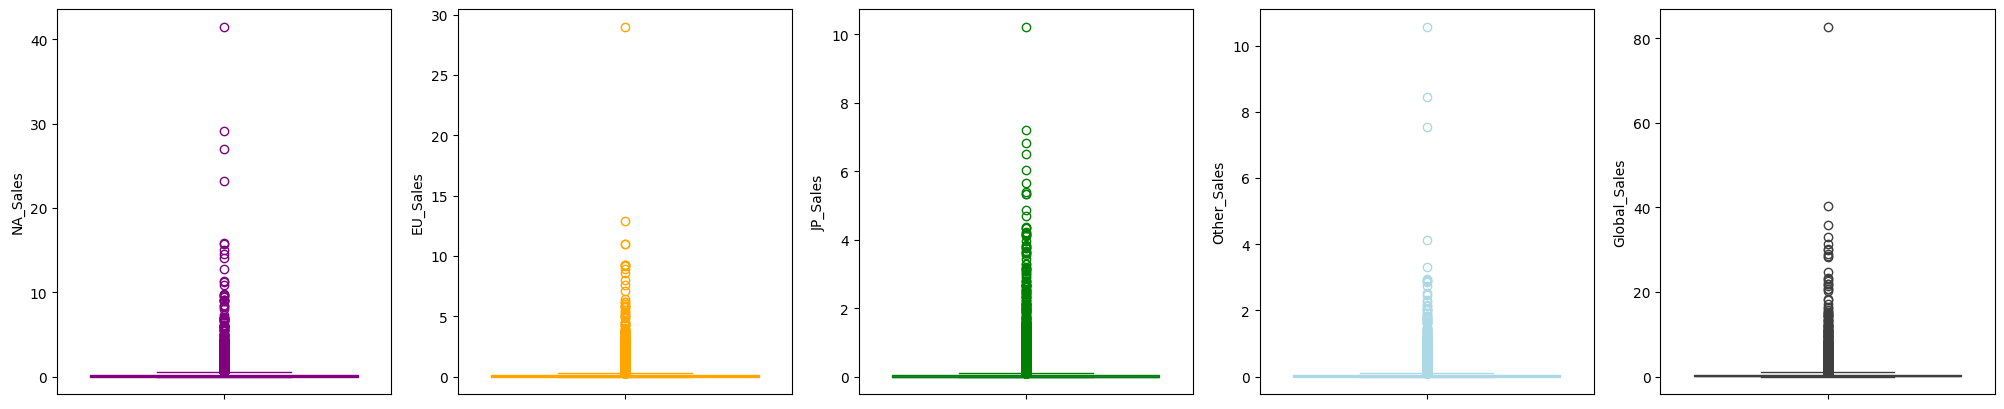

In [355]:
fig, ax=plt.subplots(1,5,figsize=(25,5))
sns.boxplot(ax=ax[0],data=df,y=df['NA_Sales'],linecolor='purple')
sns.boxplot(ax=ax[1],data=df,y='EU_Sales',linecolor='orange')
sns.boxplot(ax=ax[2],data=df,y='JP_Sales',linecolor='Green')
sns.boxplot(ax=ax[3],data=df,y='Other_Sales',linecolor="lightblue")
sns.boxplot(ax=ax[4],data=df,y=df['Global_Sales'])


Here we see sales data of all the region contains a lot of outliers.

In [356]:
sales_columns=[
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales'
    ]

for col in sales_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

NA_Sales: 1660 outliers
EU_Sales: 2054 outliers
JP_Sales: 2407 outliers
Other_Sales: 1645 outliers
Global_Sales: 1827 outliers


Japan has the highest number of outlier that that doesn't prove that the data is errorneous.Let's inspet more.

In [357]:
df.nlargest(10,['Global_Sales'])[  ['Name', 'Platform', 'Year', 'Genre',
     'Global_Sales', 'NA_Sales', 'EU_Sales',
     'JP_Sales', 'Other_Sales']]

,Name,Platform,Year,Genre,Global_Sales,NA_Sales,EU_Sales,JP_Sales,Other_Sales
0,Wii Sports,Wii,2006,Sports,82.74,41.49,29.02,3.77,8.46
1,Super Mario Bros.,NES,1985,Platform,40.24,29.08,3.58,6.81,0.77
2,Mario Kart Wii,Wii,2008,Racing,35.82,15.85,12.88,3.79,3.31
3,Wii Sports Resort,Wii,2009,Sports,33.00,15.75,11.01,3.28,2.96
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,31.37,11.27,8.89,10.22,1.00
5,Tetris,GB,1989,Puzzle,30.26,23.20,2.26,4.22,0.58
6,New Super Mario Bros.,DS,2006,Platform,30.01,11.38,9.23,6.50,2.90
7,Wii Play,Wii,2006,Misc,29.02,14.03,9.20,2.93,2.85
8,New Super Mario Bros. Wii,Wii,2009,Platform,28.62,14.59,7.06,4.70,2.26
9,Duck Hunt,NES,1984,Shooter,28.31,26.93,0.63,0.28,0.47


In [358]:
regional_sum = (
    df['NA_Sales'] +df['EU_Sales'] +df['JP_Sales'] +df['Other_Sales']
)

difference = (df['Global_Sales'] - regional_sum).abs()

print("Records with difference > 0.01:",
      (difference > 0.01).sum())

Records with difference > 0.01: 2580


In [359]:
print(difference.describe())

count    16327.000000
mean         0.002723
std          0.004465
min          0.000000
25%          0.000000
50%          0.000000
75%          0.010000
max          0.020000
dtype: float64


A consistency check was performed by comparing global sales with the sum of regional sales. Minor discrepancies of up to 0.02 million were observed, likely due to rounding. Since these differences were negligible, the records were retained without modification.

In [360]:
df.shape

(16327, 11)

In [361]:
top_5_publi

Index(['Electronic Arts', 'Activision', 'Namco Bandai Games', 'Ubisoft',
       'Konami Digital Entertainment'],
      dtype='object', name='Publisher')

In [362]:
top_5_info=df[df['Publisher'].isin(top_5_publi) & df['Platform'].isin(top_5_plat) & df['Genre'].isin(top_5_gen) ]
top_5_info.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
29,30,Call of Duty: Modern Warfare 3,X360,2011,Shooter,Activision,9.03,4.28,0.13,1.32,14.76
31,32,Call of Duty: Black Ops,X360,2010,Shooter,Activision,9.67,3.73,0.11,1.13,14.64
34,35,Call of Duty: Black Ops II,PS3,2012,Shooter,Activision,4.99,5.88,0.65,2.52,14.03
35,36,Call of Duty: Black Ops II,X360,2012,Shooter,Activision,8.25,4.30,0.07,1.12,13.73
36,37,Call of Duty: Modern Warfare 2,X360,2009,Shooter,Activision,8.52,3.63,0.08,1.29,13.51


<Axes: title={'center': 'Distribution of Game Genres Across Top 5 Publishers'}, xlabel='Publisher', ylabel='count'>

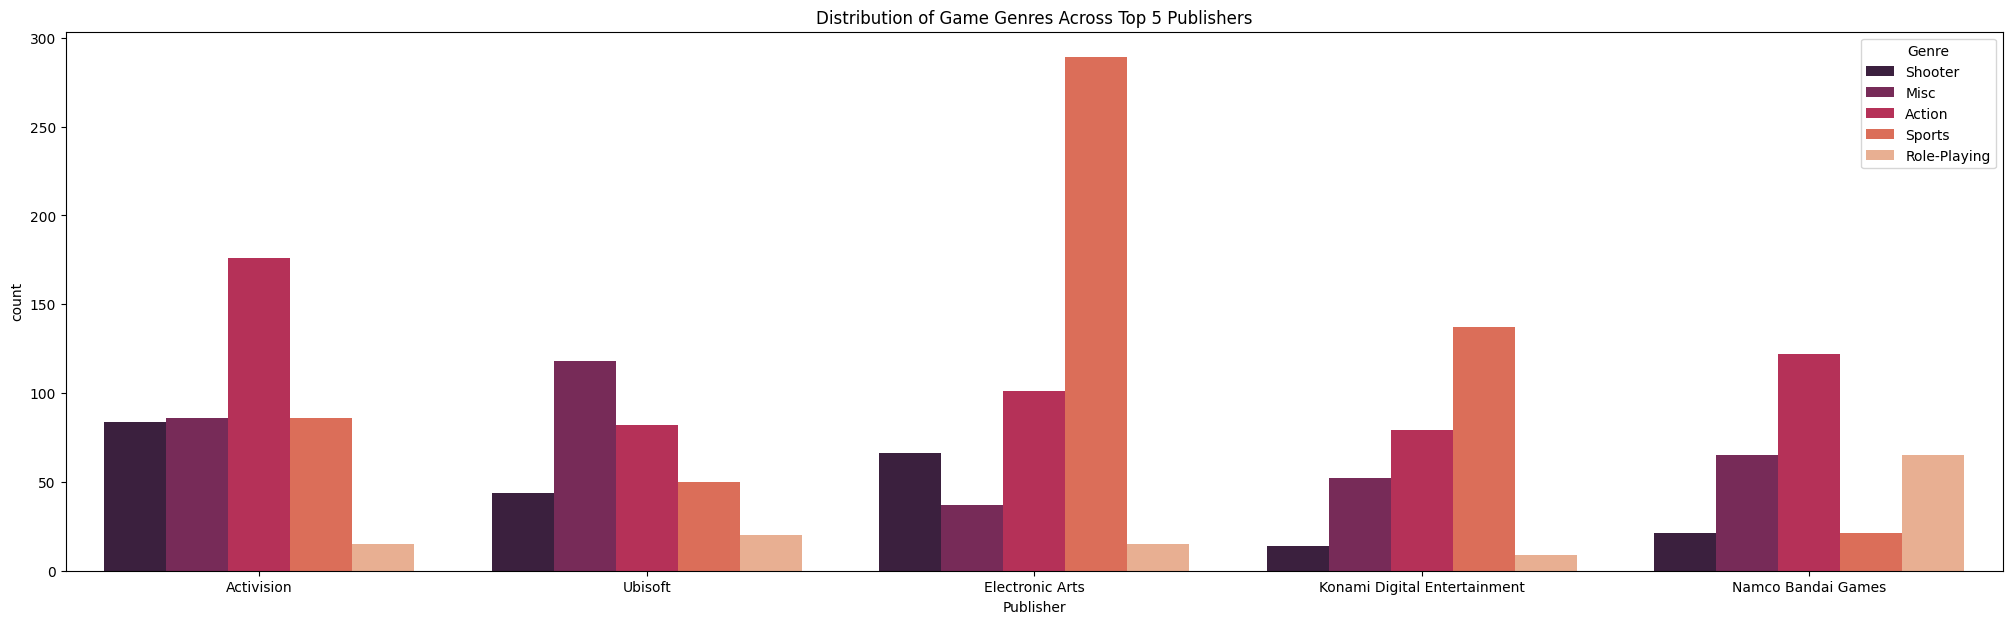

In [398]:
plt.figure(figsize=(25,7))
plt.title('Distribution of Game Genres Across Top 5 Publishers')
sns.countplot(data=top_5_info,x='Publisher',hue='Genre',palette='rocket')



Among the selected top publishers, Electronic Arts and Konami Digital Entertainment publishe the most games in the Sports genre, Ubisoft in Misc, and Activision and Namco Bandai Games in Action.


In [366]:
df.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False).head(5)

Publisher
Nintendo                       1784.43
Electronic Arts                1093.39
Activision                      721.41
Sony Computer Entertainment     607.28
Ubisoft                         473.54
Name: Global_Sales, dtype: float64

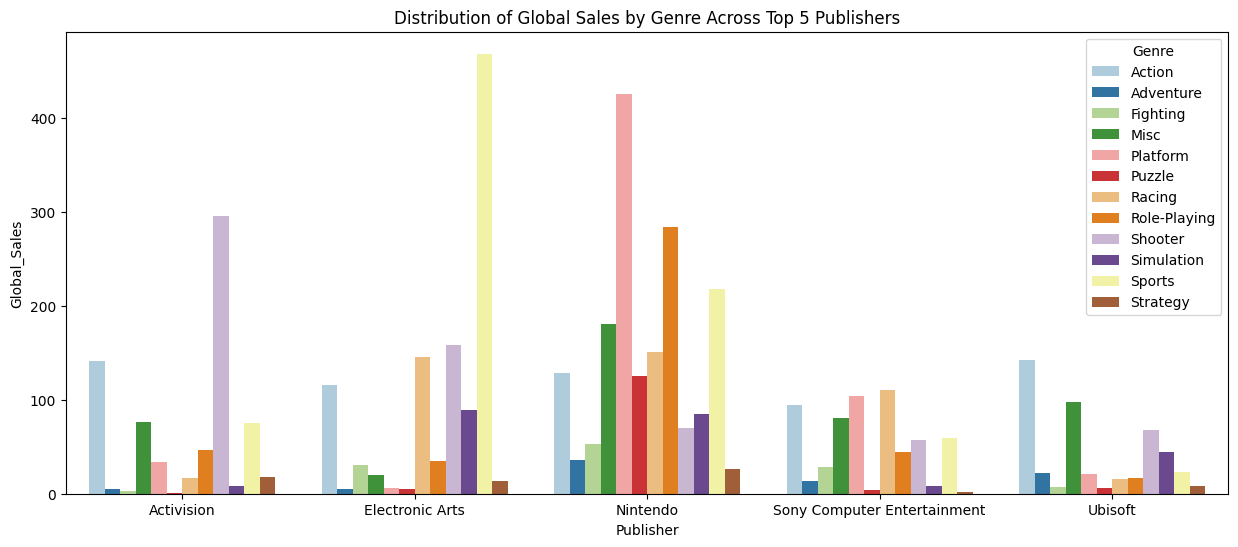

In [368]:
globalpublisher= df.groupby('Publisher')['Global_Sales'].sum().sort_values(ascending=False).head(5).index
top_5_details= df[df['Publisher'].isin(globalpublisher)]
genre_profit = top_5_details.groupby(['Publisher', 'Genre'])['Global_Sales'].sum().reset_index()
plt.figure(figsize=(15,6))
sns.barplot(data=genre_profit,x='Publisher',y='Global_Sales', hue='Genre',palette='Paired')
plt.title("Distribution of Global Sales by Genre Across Top 5 Publishers")
plt.show()




Conclusion:
- Activision: The Shooter genre makes the greatest contribution to Activision's global sales (nearly 300 million), followed by Action.
- Electronic Arts: The Sports genre overwhelmingly drives Electronic Arts' global sales (over 460 million), aligning with its high volume of Sports releases.
- Nintendo: Platform games generate the highest global sales for Nintendo (over 420 million), followed by Role-Playing and Sports. Unlike other top publishers, Nintendo shows strong revenue across multiple genres.
- Sony Computer Entertainment: Revenue is fairly balanced across its top genres, with Racing, Platform, and Action leading its global sales.
- Ubisoft: The Action genre contributes the most to Ubisoft's global sales. Although the previous chart showed Ubisoft publishes more games in the Misc genre, Action titles generate higher overall revenue, suggesting Ubisoft should continue prioritizing Action games.


### Platform analysis

In [369]:
df['Platform'].unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       '3DS', 'PS4', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne', 'GC',
       'WiiU', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

In [252]:
NA_plat=df.groupby('Platform')['NA_Sales'].sum()
NA_plat.sort_values(ascending = False).head()

Platform
X360    594.33
PS2     572.92
Wii     497.37
PS3     388.90
DS      388.56
Name: NA_Sales, dtype: float64

In North America, the Xbox 360 generates the highest video game sales at 594.33 million, narrowly outperforming the PlayStation 2 (572.92 million) and Wii (497.37 million).


In [253]:
EU_plat=df.groupby('Platform')['EU_Sales'].sum()
EU_plat.sort_values(ascending = False).head()

Platform
PS3     340.47
PS2     332.63
X360    278.01
Wii     264.35
PS      212.38
Name: EU_Sales, dtype: float64

In Europe, the PlayStation 3 generates the highest video game sales at 340.47 million, narrowly outperforming the PlayStation 2 (332.63 million) and X360 (278.01 million) in the third position.

In [254]:
JP_plat=df.groupby('Platform')['JP_Sales'].sum()
JP_plat.sort_values(ascending = False).head()

Platform
DS      175.02
PS      139.78
PS2     137.54
SNES    116.55
NES      98.65
Name: JP_Sales, dtype: float64

In Japan, the DS generates the highest video game sales at 175.02 million, outperforming the PlayStation (139.78 million) and PS2 (137.54 million).

In [384]:
other_plat=df.groupby('Platform')['Other_Sales'].sum()
other_plat.sort_values(ascending = False).head()

Platform
PS2     190.47
PS3     140.81
X360     84.67
Wii      79.20
DS       60.29
Name: Other_Sales, dtype: float64

In [385]:
global_platform=df.groupby('Platform')['Global_Sales'].sum()
global_platform.sort_values(ascending=False).head()

Platform
PS2     1233.46
X360     969.61
PS3      949.35
Wii      909.81
DS       818.96
Name: Global_Sales, dtype: float64

Globally, the PlayStation 2 leads all gaming platforms with 1,233.46 million in total sales, outperforming the Xbox 360 (969.61 million) and PlayStation 3 (949.35 million). Notably, while the Xbox 360 leads in North America, PlayStation consoles dominate overall global sales due to stronger international adoption

### Genre Analysis

In [256]:
na_gen=df.groupby('Genre')['NA_Sales'].sum()
na_gen.sort_values(ascending=False).head()

Genre
Action      861.80
Sports      670.09
Shooter     575.16
Platform    445.99
Misc        402.48
Name: NA_Sales, dtype: float64

In North America, the Action genre generates the highest video game sales at 861.80 million, well ahead from the sport genre (670.09 million) and shooter genre(575.16 million).

In [257]:
eu_gen=df.groupby('Genre')['EU_Sales'].sum()
eu_gen.sort_values(ascending=False).head()

Genre
Action     516.48
Sports     371.34
Shooter    310.45
Racing     236.32
Misc       213.82
Name: EU_Sales, dtype: float64

In Europe, the Action genre generates the highest video game sales at 516.48 million, well ahead from the sport genre (371.34 million) and shooter genre(310.45 million).

In [258]:
jp_gen=df.groupby('Genre')['JP_Sales'].sum()
jp_gen.sort_values(ascending=False).head()

Genre
Role-Playing    350.29
Action          158.66
Sports          134.76
Platform        130.65
Misc            106.67
Name: JP_Sales, dtype: float64

In Japan, the Role-playing genre generates the highest video game sales at 350.29 million, well ahead from the action genre (158.66 million) and sport genre(134.76 million).

In [386]:
other_gen=df.groupby('Genre')['Other_Sales'].sum()
other_gen.sort_values(ascending=False).head()

Genre
Action     184.92
Sports     132.65
Shooter    101.90
Racing      76.68
Misc        74.02
Name: Other_Sales, dtype: float64

In other regions, the Action genre generates the highest video game sales at 184.92 million, well ahead from the sport genre (132.65 million) and shooter genre(101.90 million).

In [399]:
global_gen=df.groupby('Genre')['Global_Sales'].sum()
global_gen=global_gen.sort_values(ascending=False).head()
global_gen

Genre
Action          1722.88
Sports          1309.24
Shooter         1026.20
Role-Playing     923.84
Platform         829.15
Name: Global_Sales, dtype: float64

The Action genre generates the highest Global Sales at 1,722.88 million, outperforming Sports (1,309.24 million) and Shooter (1,026.20 million) to lead the worldwide video game market

In [413]:
yr_gen=df.groupby(['Genre','Year'])['Global_Sales'].sum().reset_index()
top_genres = global_gen.index
refined_gen=yr_gen[yr_gen['Genre'].isin(top_genres)]
top_genres

Index(['Action', 'Sports', 'Shooter', 'Role-Playing', 'Platform'], dtype='object', name='Genre')

In [415]:
refined_gen.head()

,Genre,Year,Global_Sales
0,Action,1980,0.34
1,Action,1981,14.84
2,Action,1982,6.52
3,Action,1983,2.86
4,Action,1984,1.85


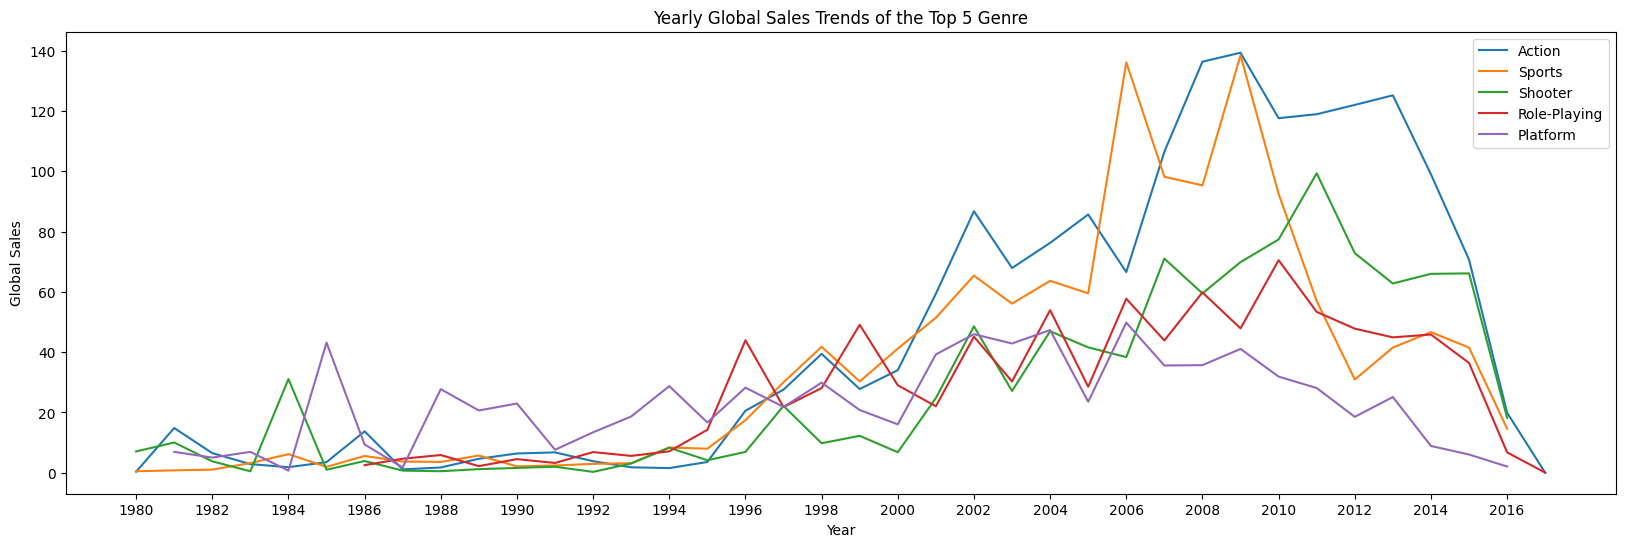

In [426]:
plt.figure(figsize=(20,6))

for genre in top_genres:
    gen_data = refined_gen[refined_gen['Genre'] == genre]
    plt.plot(gen_data['Year'], gen_data['Global_Sales'], label=genre)

plt.xlabel('Year')
plt.ylabel('Global Sales')
plt.title('Yearly Global Sales Trends of the Top 5 Genre')
plt.legend()
x_ax=np.arange(1980,2017,2)
plt.xticks(x_ax)
plt.show()

Global video game sales across the top five genres grew slowly until 2000, surged during the late 2000s, and declined sharply after 2013. Platform games led the early decades, while Action and Sports drove the peak era—both reaching nearly 140 million in annual sales between 2006 and 2009—before sales dropped off across all genres toward 2016–2017.

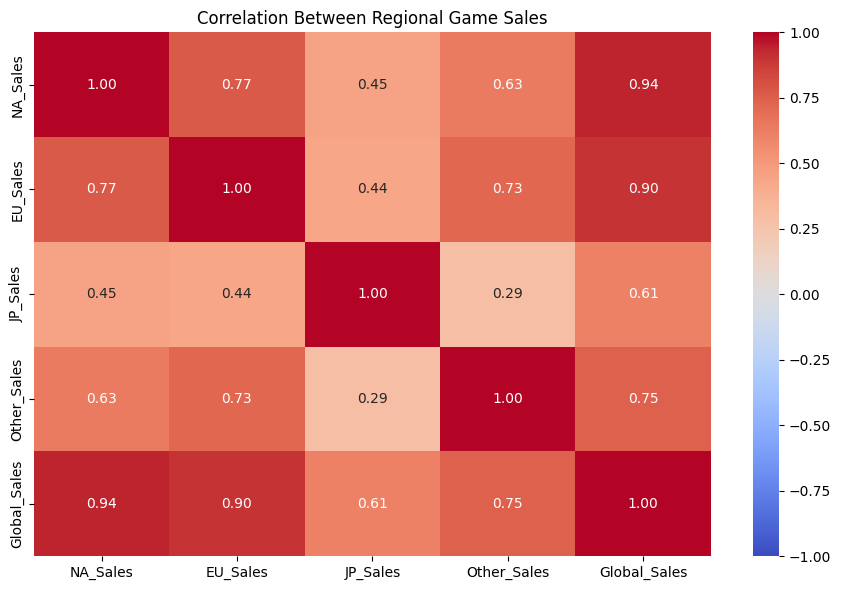

In [430]:
regional_corr = df[
    ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales','Global_Sales']
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    regional_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Between Regional Game Sales')
plt.tight_layout()
plt.show()

The correlation analysis reveals positive relationships between sales across geographical regions.

North American and European sales show a strong positive correlation (0.77), suggesting that games performing well in one market tend to perform well in the other. European and Other-region sales also exhibit a relatively strong positive correlation (0.73).

Japanese sales show comparatively weaker correlations with the other regions, particularly Other-region sales (0.29). This suggests that Japanese sales patterns differ somewhat from those of other markets.


In [421]:
pub_gen=df.groupby(['Genre','Publisher'])['Global_Sales'].sum().reset_index()
best_publisher_per_genre = (pub_gen.loc[pub_gen.groupby('Genre')['Global_Sales'].idxmax()].sort_values(by='Global_Sales', ascending=False))
best_publisher_per_genre


,Genre,Publisher,Global_Sales
1592,Sports,Electronic Arts,468.69
804,Platform,Nintendo,426.18
1246,Shooter,Activision,295.40
1192,Role-Playing,Nintendo,284.57
198,Action,Take-Two Interactive,211.08
663,Misc,Nintendo,180.67
1026,Racing,Nintendo,151.30
908,Puzzle,Nintendo,124.88
1430,Simulation,Electronic Arts,89.53
511,Fighting,THQ,72.86


This data clearly mentions the best publisher for each Genre.


#### Some useful insights

In [438]:
top_5_publi

Index(['Electronic Arts', 'Activision', 'Namco Bandai Games', 'Ubisoft',
       'Konami Digital Entertainment'],
      dtype='object', name='Publisher')

In [449]:
ea_data=df[df['Publisher']=='Electronic Arts'].copy()

In [459]:
ea_NA_combinations=ea_data.groupby(['Genre','Platform']).agg(Total_NA_Sales=('NA_Sales','sum'),Published_Game_Counts=('Name','count'),Average_Sales=('Global_Sales','mean'))
ea_NA_combinations.sort_values('Total_NA_Sales',ascending=False).head()

Total_NA_Sales  Published_Game_Counts  Average_Sales
Genre   Platform                                                      
Sports  PS2                75.72                    101       1.251386
        X360               46.98                     73       1.032740
        PS3                33.54                     64       1.211875
Shooter X360               24.58                     22       1.811364
Sports  PS                 22.95                     39       0.916667

In [451]:
ea_europe_combinations = ea_data.groupby(['Genre', 'Platform']).agg(Total_EU_Sales=('EU_Sales', 'sum'),Published_Game_Count=('Name', 'count'),Average_Sales=('EU_Sales', 'mean')).sort_values('Total_EU_Sales', ascending=False)
ea_europe_combinations.head(10)

Total_EU_Sales  Published_Game_Count  Average_Sales
Genre      Platform                                                     
Sports     PS3                31.21                    64       0.487656
           PS2                27.60                   101       0.273267
           X360               21.79                    73       0.298493
           PS4                18.08                    16       1.130000
Simulation PC                 17.79                    45       0.395333
Racing     PS2                13.42                    29       0.462759
Action     PS3                11.38                    28       0.406429
Shooter    X360               11.23                    22       0.510455
           PS3                11.10                    17       0.652941
Sports     PS                 10.33                    39       0.264872

In [454]:
ea_japan_combinations=ea_data.groupby(['Genre','Platform']).agg(Total_JP_Sales=('JP_Sales','sum'),Published_Game_Count=('Name','count'),Average_Sales=('Global_Sales','mean'))
ea_japan_combinations.sort_values('Total_JP_Sales',ascending=False).head()

Total_JP_Sales  Published_Game_Count  Average_Sales
Genre        Platform                                                     
Role-Playing PS2                 2.11                     2       2.935000
Sports       PS2                 1.33                   101       1.251386
Action       PS2                 1.24                    19       1.056842
Shooter      PS3                 1.03                    17       1.634706
             PS2                 0.83                    20       1.434000

In [457]:
ea_other_combinations=ea_data.groupby(['Genre','Platform']).agg(Total_other_Sales=('Other_Sales','sum'),Published_Game_Count=('Name','count'),Average_Sales=('Global_Sales','mean'))
ea_other_combinations.sort_values('Total_other_Sales',ascending=False).head()

Total_other_Sales  Published_Game_Count  Average_Sales
Genre  Platform                                                        
Sports PS2                   21.69                   101       1.251386
       PS3                   12.17                    64       1.211875
Racing PS2                    7.28                    29       1.433103
Sports X360                   6.39                    73       1.032740
       PS4                    5.55                    16       2.124375

Based on the analysis of different genre-platform performance of Electronic Arts in different regions we can conclude that.
- In North America,Europe and Other regions, data indicates that Sport genre in Play Station 2 would be beneficial for Electronic Arts.
- In  Japan, data indicates Play Station 2 platform to be a favourable platform,but choosing the right genre is less straightforward. Role-Playing  has a total sales of 2.11 M in japan with an average of 2.93M but the sample size (2) is small to draw a conclusion.Similarly for shooter genre the average_Sales(1.63) looks tempting but the sample size is smaller than sports genre(101) again whose average sales is 1.25.

C:\Users\priya\Desktop\python_project\data_analysis\videogame.ipynb